# Importing all neccessary libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Loading the dataset

In [3]:
df=pd.read_csv('hospital data analysis.csv')

# Exploring the dataset

In [8]:
df.head()

,Patient_ID,Age,Gender,Condition,Procedure,Cost,Length_of_Stay,Readmission,Outcome,Satisfaction
0,1,45,Female,Heart Disease,Angioplasty,15000,5,No,Recovered,4
1,2,60,Male,Diabetes,Insulin Therapy,2000,3,Yes,Stable,3
2,3,32,Female,Fractured Arm,X-Ray and Splint,500,1,No,Recovered,5
3,4,75,Male,Stroke,CT Scan and Medication,10000,7,Yes,Stable,2
4,5,50,Female,Cancer,Surgery and Chemotherapy,25000,10,No,Recovered,4


In [9]:
print(df.head(100))

    Patient_ID  Age  Gender              Condition                  Procedure  \
0            1   45  Female          Heart Disease                Angioplasty   
1            2   60    Male               Diabetes            Insulin Therapy   
2            3   32  Female          Fractured Arm           X-Ray and Splint   
3            4   75    Male                 Stroke     CT Scan and Medication   
4            5   50  Female                 Cancer   Surgery and Chemotherapy   
..         ...  ...     ...                    ...                        ...   
95          97   45  Female           Appendicitis               Appendectomy   
96          98   40    Male          Fractured Leg  Cast and Physical Therapy   
97          99   78  Female           Heart Attack    Cardiac Catheterization   
98         100   25    Male      Allergic Reaction      Epinephrine Injection   
99         101   52  Female  Respiratory Infection       Antibiotics and Rest   

     Cost  Length_of_Stay R

In [10]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 984 entries, 0 to 983
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Patient_ID      984 non-null    int64 
 1   Age             984 non-null    int64 
 2   Gender          984 non-null    object
 3   Condition       984 non-null    object
 4   Procedure       984 non-null    object
 5   Cost            984 non-null    int64 
 6   Length_of_Stay  984 non-null    int64 
 7   Readmission     984 non-null    object
 8   Outcome         984 non-null    object
 9   Satisfaction    984 non-null    int64 
dtypes: int64(5), object(5)
memory usage: 77.0+ KB
None


In [11]:
print(df.describe())

        Patient_ID         Age          Cost  Length_of_Stay  Satisfaction
count   984.000000  984.000000    984.000000      984.000000    984.000000
mean    500.329268   53.754065   8367.479675       37.663618      3.598577
std     288.979531   14.941135   7761.990976       19.595805      0.883002
min       1.000000   25.000000    100.000000        1.000000      2.000000
25%     250.750000   45.000000   1000.000000       21.000000      3.000000
50%     500.500000   55.000000   6000.000000       38.000000      4.000000
75%     750.250000   65.000000  15000.000000       54.250000      4.000000
max    1000.000000   78.000000  25000.000000       76.000000      5.000000


In [12]:
print(df.columns)

Index(['Patient_ID', 'Age', 'Gender', 'Condition', 'Procedure', 'Cost',
       'Length_of_Stay', 'Readmission', 'Outcome', 'Satisfaction'],
      dtype='object')


# Metadata

# Cleaning of Data

In [13]:
df.dropna().value_counts()

Patient_ID  Age  Gender  Condition              Procedure                             Cost   Length_of_Stay  Readmission  Outcome    Satisfaction
1           45   Female  Heart Disease          Angioplasty                           15000  5               No           Recovered  4               1
657         67   Male    Prostate Cancer        Radiation Therapy                     20000  52              No           Recovered  3               1
659         50   Male    Kidney Stones          Lithotripsy                           6000   47              No           Recovered  3               1
660         60   Female  Osteoarthritis         Physical Therapy and Pain Management  4000   48              No           Stable     4               1
662         65   Male    Diabetes               Insulin Therapy                       2000   47              No           Stable     3               1
                                                                                                   

In [14]:
df.drop_duplicates().value_counts()

Patient_ID  Age  Gender  Condition              Procedure                             Cost   Length_of_Stay  Readmission  Outcome    Satisfaction
1           45   Female  Heart Disease          Angioplasty                           15000  5               No           Recovered  4               1
657         67   Male    Prostate Cancer        Radiation Therapy                     20000  52              No           Recovered  3               1
659         50   Male    Kidney Stones          Lithotripsy                           6000   47              No           Recovered  3               1
660         60   Female  Osteoarthritis         Physical Therapy and Pain Management  4000   48              No           Stable     4               1
662         65   Male    Diabetes               Insulin Therapy                       2000   47              No           Stable     3               1
                                                                                                   

In [15]:
df.isna().sum().sum()

np.int64(0)

In [16]:
df.duplicated().sum().sum()

np.int64(0)

# Exploratory Data Analysis (EDA)

In [17]:
len(df)

984

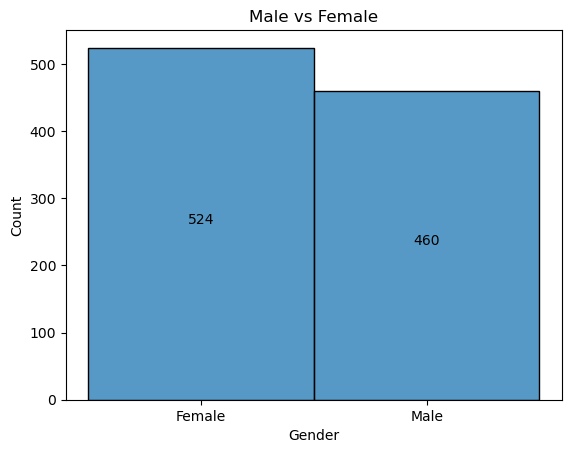

In [19]:
ax=sns.histplot(df['Gender'],bins=30)
plt.title("Male vs Female")
for container in ax.containers:
    ax.bar_label(container,fmt="%.0f",padding=3,label_type="center")

Text(0.5, 1.0, 'Average age of Male and Female')

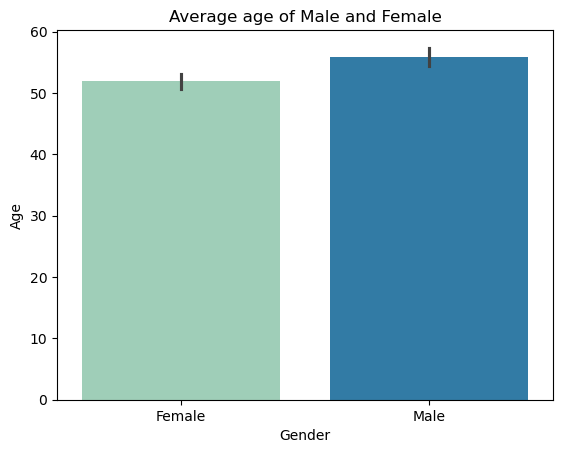

In [33]:
sns.barplot(data=df,x='Gender',y='Age',hue="Gender",palette="YlGnBu")
plt.title("Average age of Male and Female")

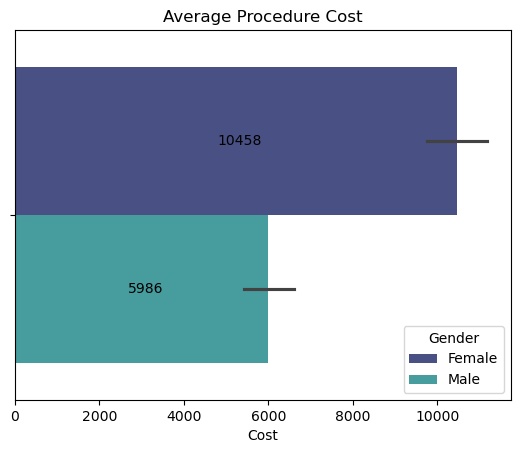

In [18]:
ax= sns.barplot(data=df,x='Cost',hue="Gender",palette="mako")
plt.title("Average Procedure Cost")
for container in ax.containers:
    ax.bar_label(container,fmt="%.0f",padding=3,label_type="center")

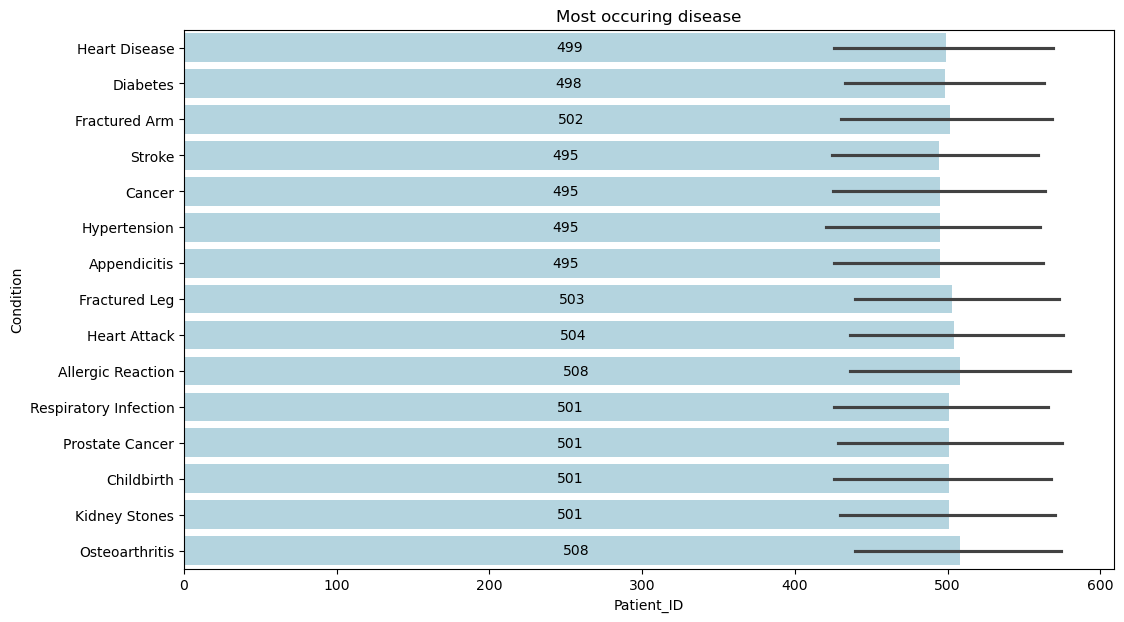

In [29]:
plt.figure(figsize=(12,7))
plt.title("Most occuring disease")
ax=sns.barplot(data=df,y='Condition',x='Patient_ID',color='lightblue')
for container in ax.containers:
    ax.bar_label(container,fmt="%.0f",padding=3,label_type="center")


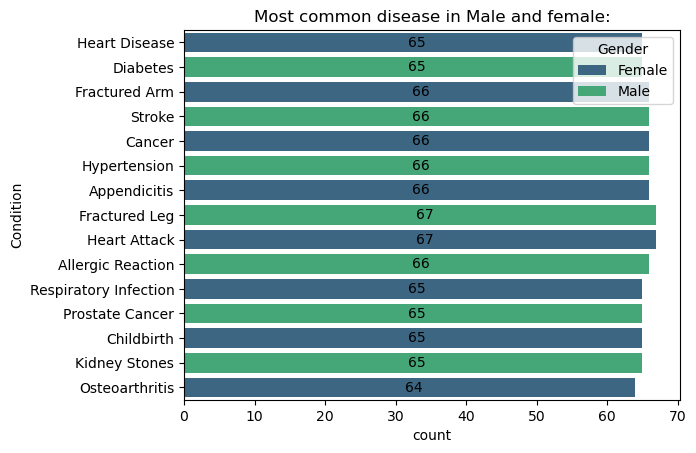

In [33]:
plt.title("Most common disease in Male and female:")
ax=sns.countplot(data=df,y='Condition',hue='Gender',palette='viridis')
for container in ax.containers:
    ax.bar_label(container,fmt="%.0f",padding=3,label_type="center")

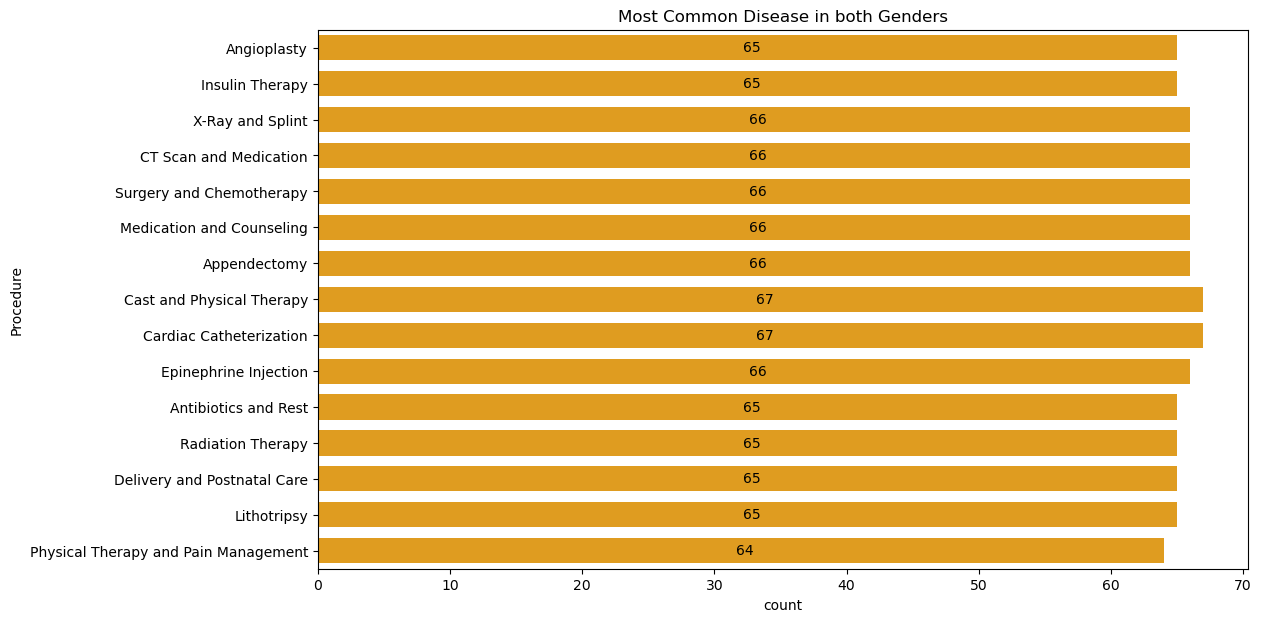

In [26]:
plt.figure(figsize=(12,7))
ax = sns.countplot(data=df,y='Procedure',width=0.7,color='orange')
plt.title("Most Common Disease in both Genders")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3,label_type='center')
    

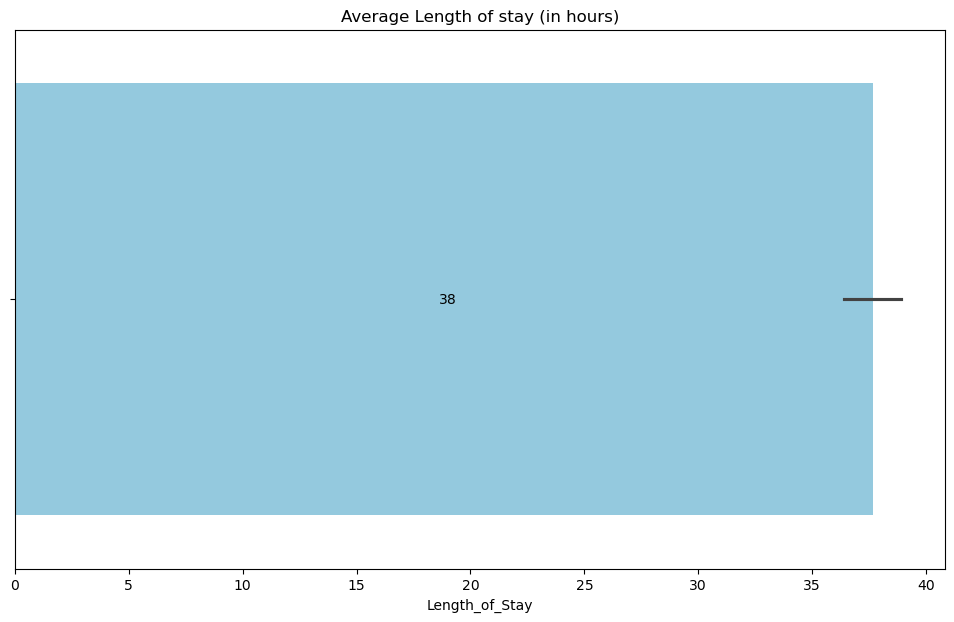

In [17]:
plt.figure(figsize=(12,7))
ax=sns.barplot(data=df,x='Length_of_Stay',color='skyblue')
plt.title("Average Length of stay (in hours)")
for container in ax.containers:
    ax.bar_label(container,fmt='%.0f',padding=3,label_type='center')

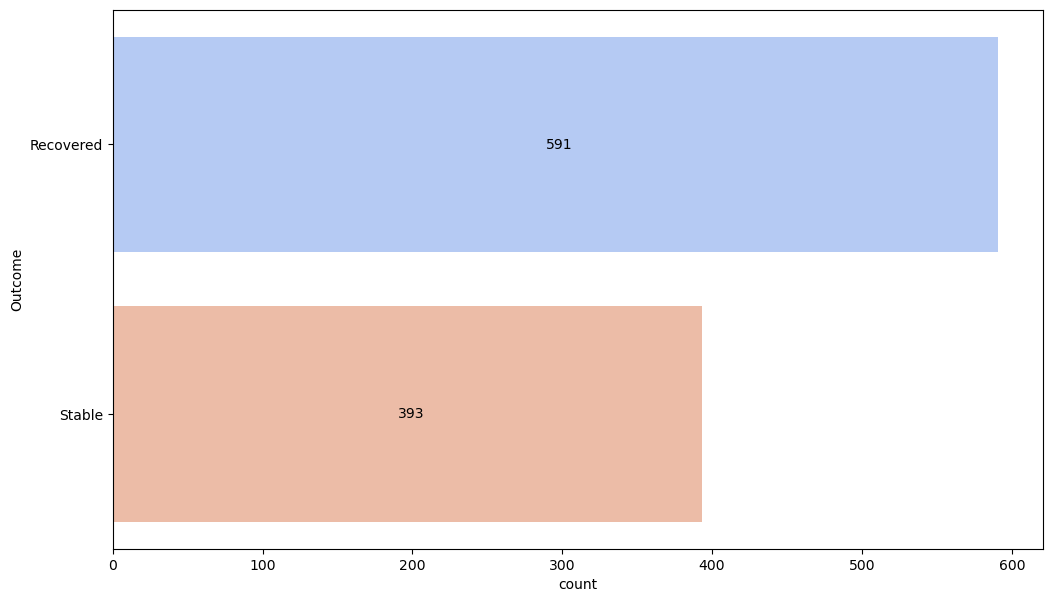

In [42]:
plt.figure(figsize=(12,7))
ax=sns.countplot(data=df,y="Outcome",hue="Outcome",palette="coolwarm")
for container in ax.containers:
    ax.bar_label(container,fmt='%.0f',padding=3,label_type='center')